# Entropy Calculation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from qss.entropy import entropy
from qss.distributions import prepare_2D_lattice_data, DistType
import tools.scientific_plot as sp


## 2D Lattice

In [3]:
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Entropy

In [ ]:
mu = Path("chemical_potential_results.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    beta = 1/k_BT
    H_a = np.unique(mu_df["H_a"])

    if "entropy" in mu_df.columns:
        entropy_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
    else:
        mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
        entropy_df = entropy(mu_df, e_k)
        entropy_df.to_csv("chemical_potential_results.csv")

else:
    raise("Lack of the calculated chemical potential! Please run notebook number 2")
entropy_df

mu  iterations  converged      residual  \
distro n        k_BT    H_a                                                    
FD     0.010000 100.000 0.0 -529.341704          23       True  8.402876e-09   
       0.061579 100.000 0.0 -344.941567          22       True  6.643114e-08   
       0.113158 100.000 0.0 -281.397501          23       True  5.165324e-08   
       0.164737 100.000 0.0 -241.068871          22       True  1.338072e-07   
       0.216316 100.000 0.0 -210.978465          20       True  9.087079e-08   
...                                 ...         ...        ...           ...   
SSL    0.783684 0.001   0.1    1.285768          24       True  2.972080e-08   
       0.835263 0.001   0.1    1.640127          20       True  3.560429e-08   
       0.886842 0.001   0.1    2.033109          19       True  8.407365e-08   
       0.938421 0.001   0.1    2.450030          16       True  1.590993e-07   
       0.990000 0.001   0.1    2.904048          21       True  8.502150e-08   

                              entropy  
distro n        k_BT    H_a            
FD     0.010000 100.000 0.0  0.062957  
       0.061579 100.000 0.0  0.274945  
       0.113158 100.000 0.0  0.434886  
       0.164737 100.000 0.0  0.569016  
       0.216316 100.000 0.0  0.685273  
...                               ...  
SSL    0.783684 0.001   0.1  0.542702  
       0.835263 0.001   0.1  0.579859  
       0.886842 0.001   0.1  0.615402  
       0.938421 0.001   0.1  0.650529  
       0.990000 0.001   0.1  0.686526  

[1200 rows x 5 columns]

#### $\frac{S} {k_B N} = f(n)$

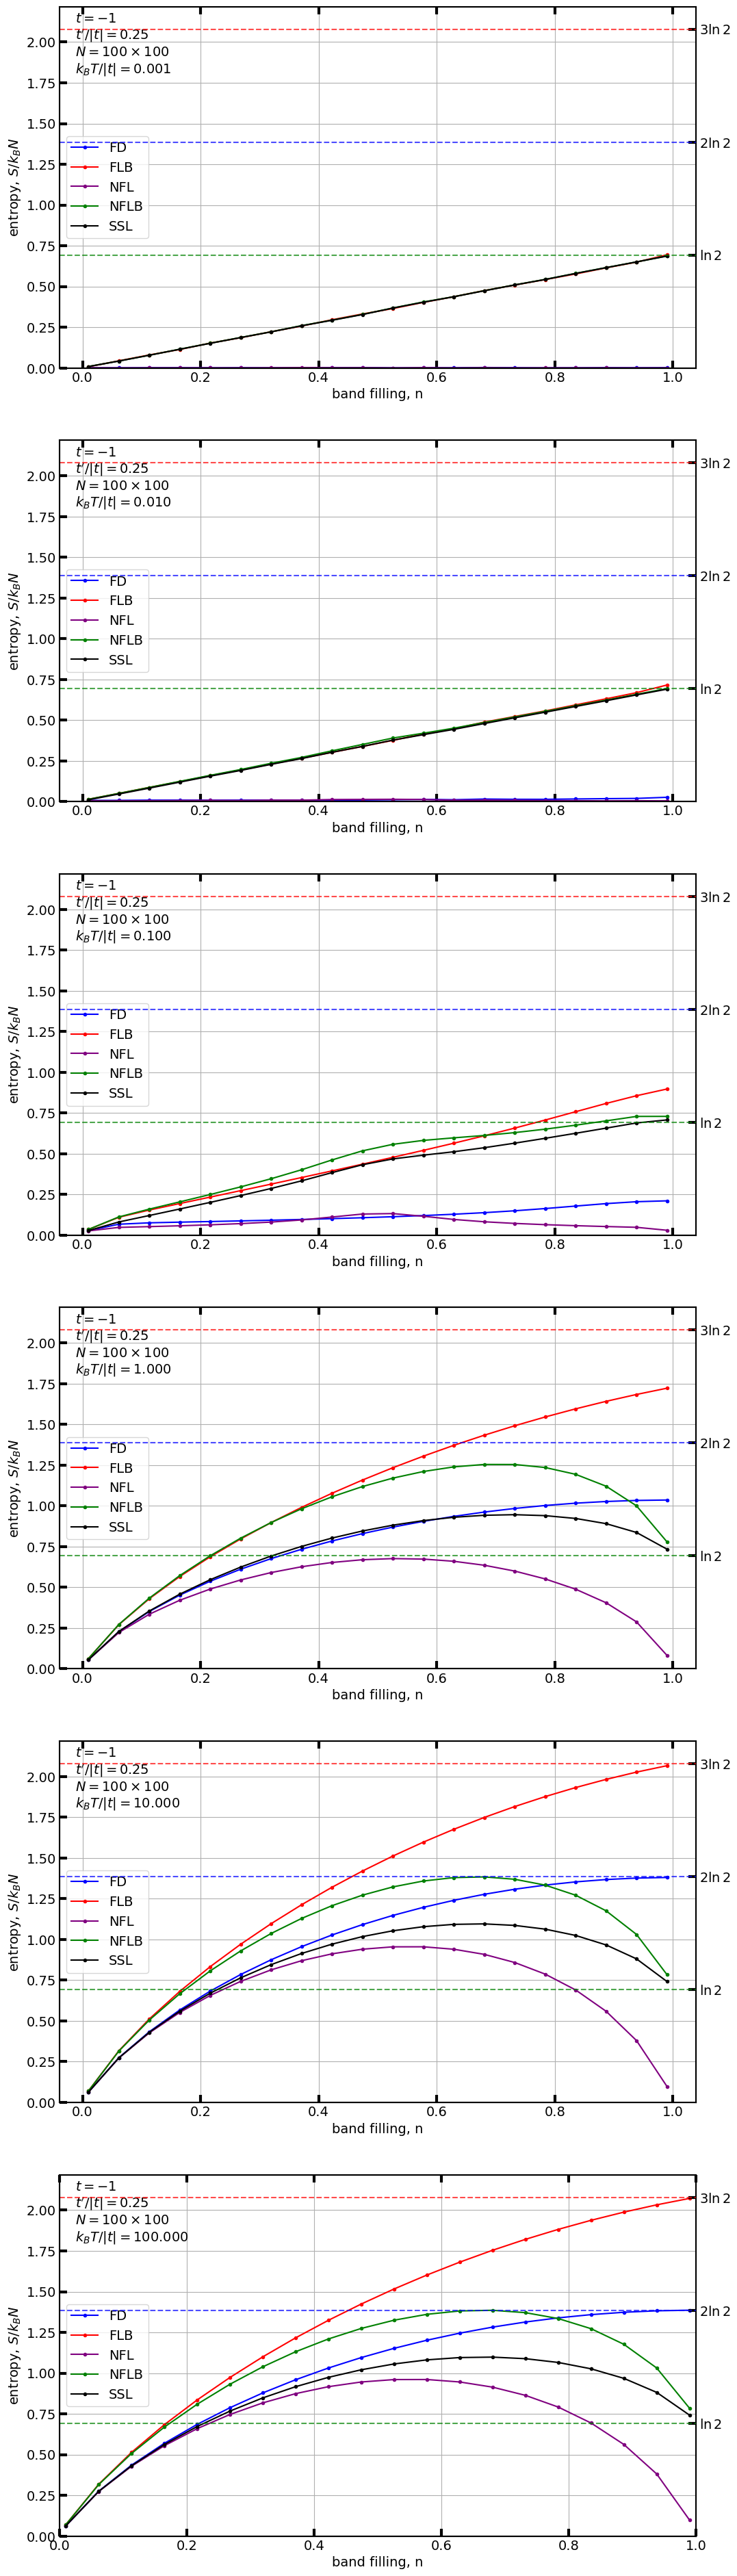

In [5]:
H_a_plot = H_a[1] 
beta_plot = 1/k_BT

# Plotimport scientific_plot as sp
sp.plot_result_n(
    results=entropy_df,
    n=n,
    betas=beta_plot,
    y_label=r"entropy, $S / k_B N$",
    distros=distro,
    H_a=H_a_plot,
    y_col="entropy",  # Specify the column to plot
    legend_position="center left",
    figsize=(12, 8),
    cols=1, # Adjust columns for layout
    show_log_vals=True,
    fontsize=14,
    
)
plt.xlim(0,1)
plt.show()

### $\frac{S} {k_B N} = f(k_BT)$


<Figure size 640x480 with 0 Axes>

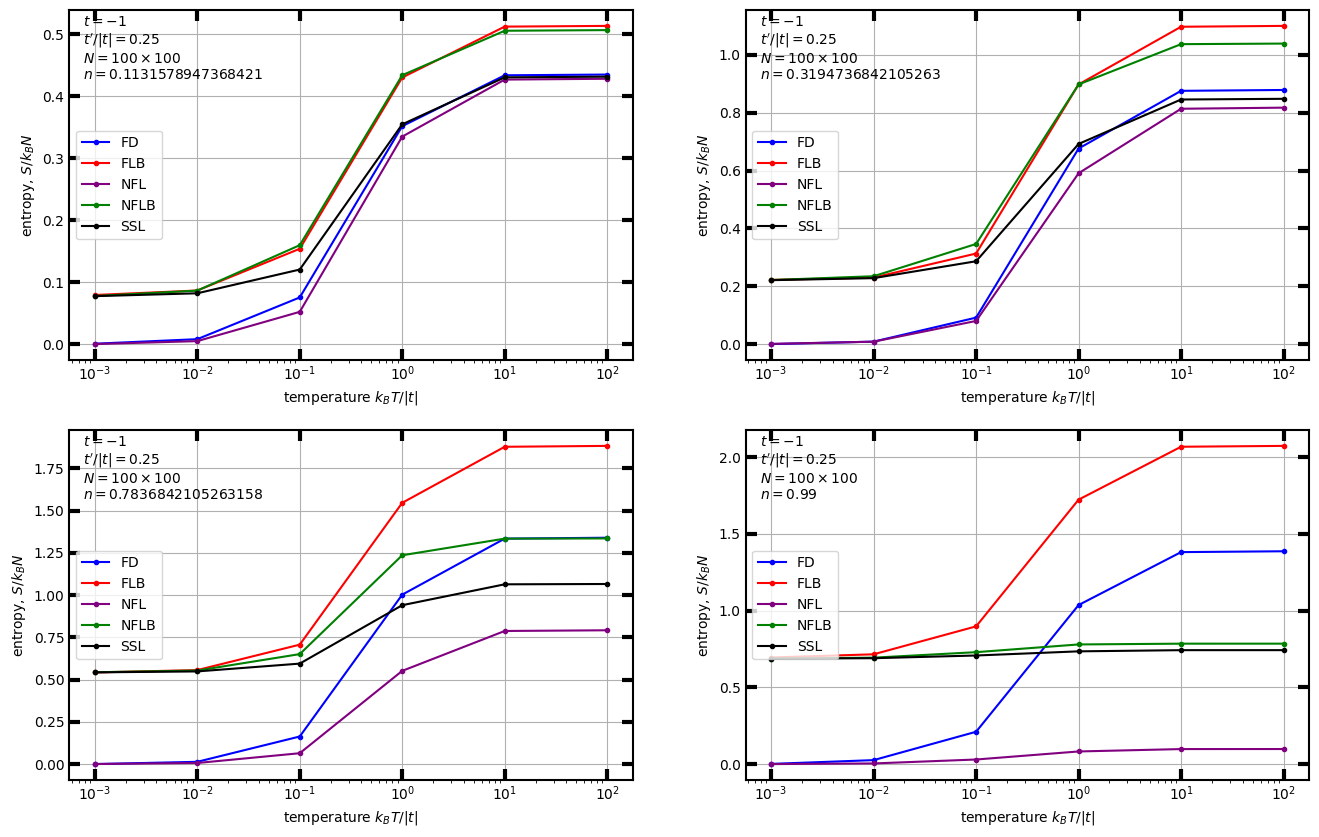

In [6]:
n_plot = [n[2], n[6], n[-5], n[-1]]
H_a_plot = H_a[0]

# Plotimport scientific_plot as sp
sp.plot_results_temperature(
    results=entropy_df,
    n=n_plot,
    betas=1/k_BT,
    y_label=r"entropy, $S / k_B N$",
    distros=distro,
    H_a=H_a_plot,
    y_col="entropy",  # Specify the column to plot
    legend_position="center left",
    figsize=(8, 5),
    cols=2 # Adjust columns for layout
)
plt.show()

#### $\frac{S} {k_B N} = f(H_a)$

<Figure size 640x480 with 0 Axes>

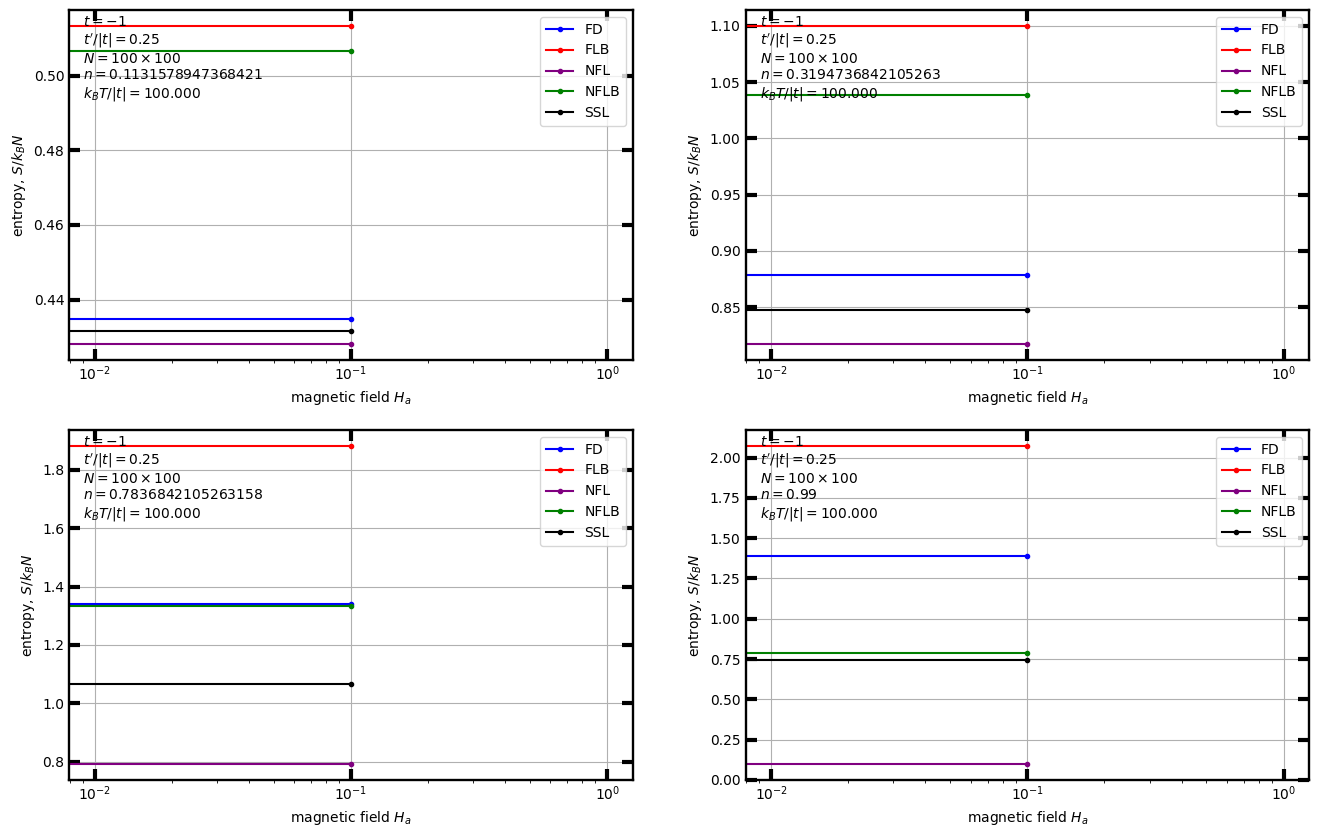

In [7]:
n_plot = [n[2], n[6], n[-5], n[-1]]
beta_plot = 1/k_BT[-1]
sp.plot_results_Ha(
    results=entropy_df,
    n=n_plot,          # List of n values to create subplots for
    beta=beta_plot,     # Fixed beta value
    y_label=r"entropy, $S / k_B N$",
    distros=distro,
    y_col="entropy",
    legend_position="upper right",
    figsize=(8, 5),
    cols=2
)
plt.show()

#### $\frac{S} {k_B N} = f(n, k_BT)$

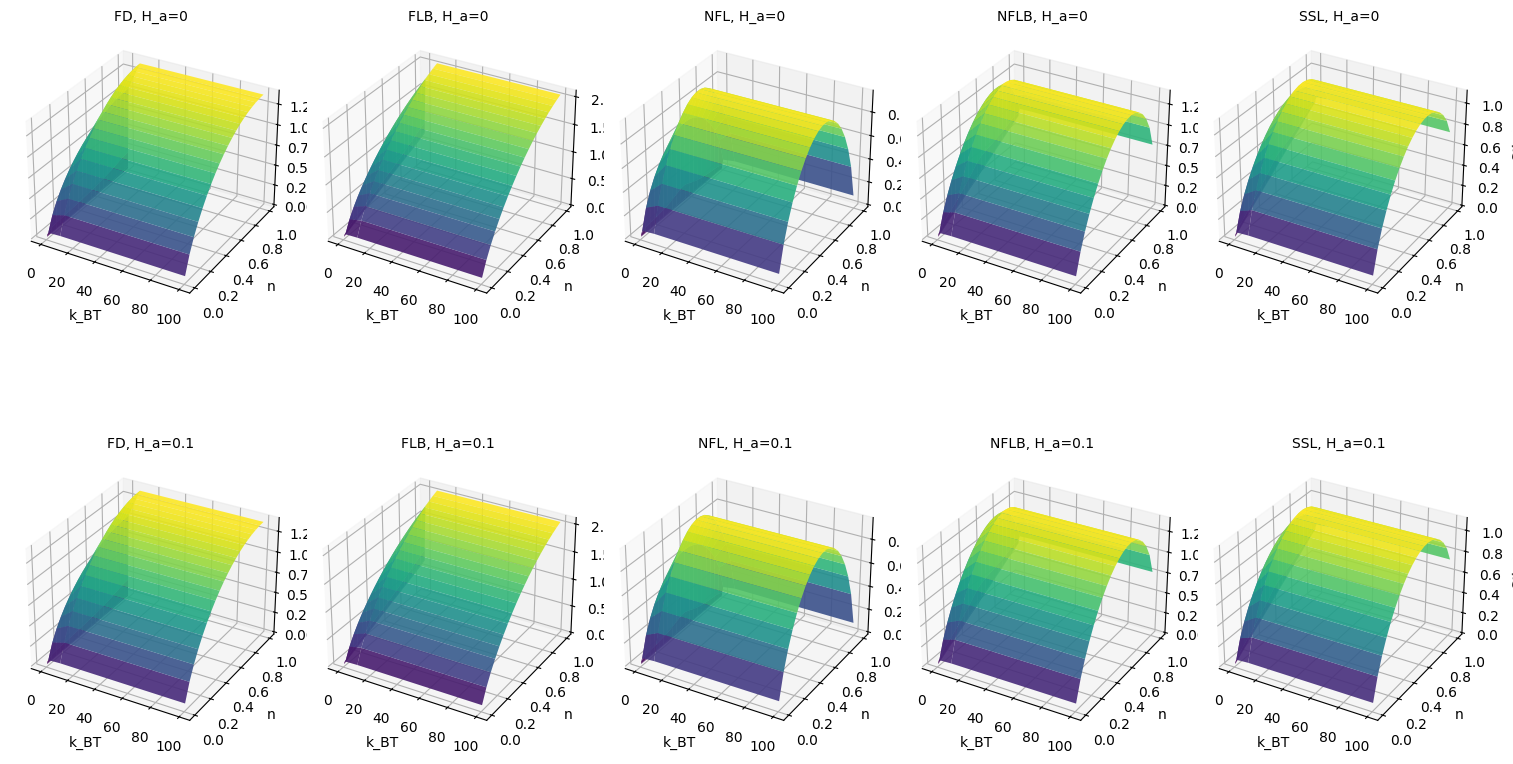

In [8]:
# Example: Plot Entropy vs Temperature (k_BT) and Magnetic Field (H_a)
# for different band fillings (n)

# Select a few n values for the rows
sp.plot_3d_results(
    results=entropy_df,
    row_param="H_a",       # Vary n across rows
    row_vals=H_a,     # Specific n values
    x_param="k_BT",      # X axis
    y_param="n",       # Y axis
    z_label=r"$S / k_B N$",
    z_col="entropy",          # or "entropy" if you have calculated it
    distros=distro,
    # figsize=(15, 10)
)
plt.show()